In [1]:
# conda at3d_pure_k9
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

In [17]:
import src.Retrieval as retrieval
plt.style.use('seaborn-v0_8-paper')

In [3]:
vDir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V10'
rdef = retrieval.Retrieval(vDir / 'default')
rdef.load_retrieval()
rloo = retrieval.Retrieval(vDir / 'LOO_BF')
rloo.load_retrieval()

In [4]:
loo_sensor_dict = rdef.sensors_retrieval.make_forward_sensors()
loo_sensor_dict.get_measurements(rloo.solvers_retrieval, n_jobs=4, verbose=True)

  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -0.892  0.410E+00    63375   256.00  1.000   [Radiance 0.670 micron]
     2  -1.447  0.416E+00    63375   256.00  1.000   [Radiance 0.670 micron]
     3  -1.946  0.418E+00    63375   256.00  1.000   [Radiance 0.670 micron]
     4  -2.209  0.192E+00    64768   256.00  1.000   [Radiance 0.670 micron]
     5  -2.233  0.997E-01    73978   256.00  1.000   [Radiance 0.670 micron]
     6  -2.201  0.702E-01    85750   256.00  1.000   [Radiance 0.670 micron]
     7  -2.332  0.606E-01    92893   256.00  1.000   [Radiance 0.670 micron]
     8  -2.401  0.503E-01   103930   256.00  1.000   [Radiance 0.670 micron]
     9  -2.367  0.431E-01   117040   256.00  1.000   [Radiance 0.670 micron]
    10  -2.114  0.411E-01   124530   256.00  1.000   [Radiance 0.670 micron]
    11  -2.249  0.412E-01   124802   256.00  1.000   [Radiance 0.670 micron]
    12  -2.707  0.411E-01   124971   256.00  1.000   [Radiance 0.670 micron]
  

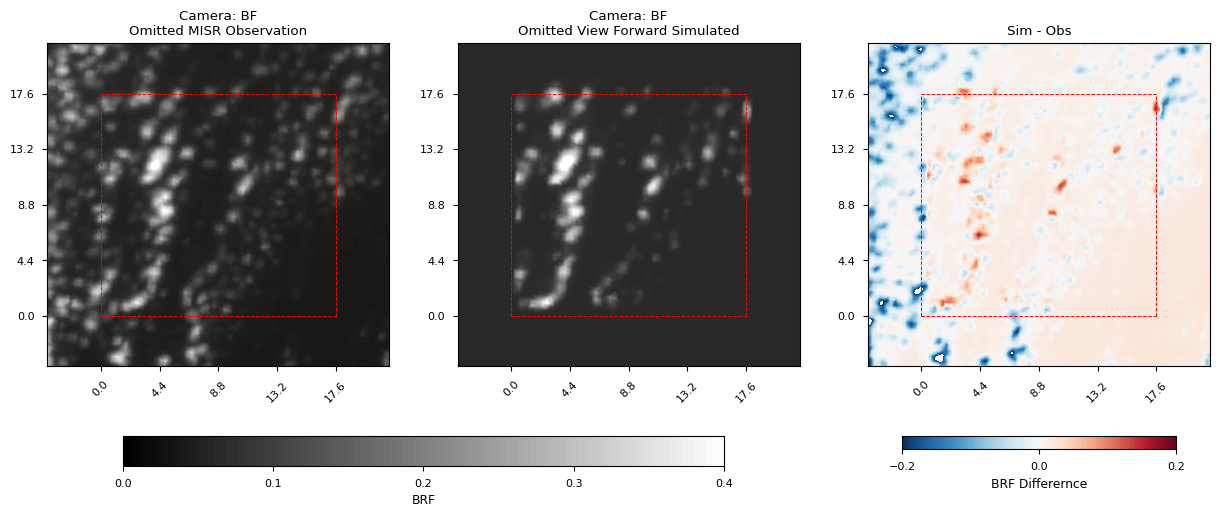

In [33]:
brf_kwargs = {
    'cmap': 'gray',
    'vmin': 0.0,
    'vmax': 0.4,
    'levels': np.linspace(0, 0.4, 100)
}
diff_kwargs = {
    'cmap': 'RdBu_r',
    'vmin': -0.2,
    'vmax': 0.2,
    'levels': np.linspace(-0.2, 0.2, 100)
}
f, ax = plt.subplots(1, 3, figsize=(15, 6))
bf_obs = rdef.obs['MISR']['sensor_list'][2].copy(deep=True)
bf_loo = loo_sensor_dict['MISR']['sensor_list'][2].copy(deep=True)
bf_loo['brf'] = (bf_loo.I * np.pi) / bf_loo.mu0.data
p0 = ax[0].tricontourf(
    bf_obs.ray_x.data,
    bf_obs.ray_y.data,
    bf_obs.brf.data,
    **brf_kwargs
)
p1 = ax[1].tricontourf(
    bf_loo.ray_x.data,
    bf_loo.ray_y.data,
    bf_loo.brf.data,
    **brf_kwargs
)
p2 = ax[2].tricontourf(
    bf_loo.ray_x.data,
    bf_loo.ray_y.data,
    bf_loo.brf.data - bf_obs.brf.data,
    **diff_kwargs
)
plt.colorbar(p1, ax=ax[0:2], label='BRF', shrink=0.8, ticks=[0.0, 0.1, 0.2, 0.3, 0.4], location='bottom')
plt.colorbar(p2, ax=ax[2], label='BRF Differernce', shrink=0.8, ticks=[diff_kwargs['vmin'], 0, diff_kwargs['vmax']], location='bottom')
ax[0].set_title('Camera: BF\nOmitted MISR Observation')
ax[1].set_title('Camera: BF\nOmitted View Forward Simulated')
ax[2].set_title('Sim - Obs')

box_kwargs = {'ls':'--', 'lw':0.7, 'c':'r'}
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
for a in ax.flat:
    a.plot([0, 0], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [0, 0], **box_kwargs)
    a.plot([17.6, 17.6], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [17.6, 17.6], **box_kwargs)
    a.set_xticks(ticks)
    a.set_xticklabels(ticks, rotation=45)
    a.set_yticks(ticks)
    a.set_xlim([-4,17.6+4])
    a.set_ylim([-4,17.6+4])

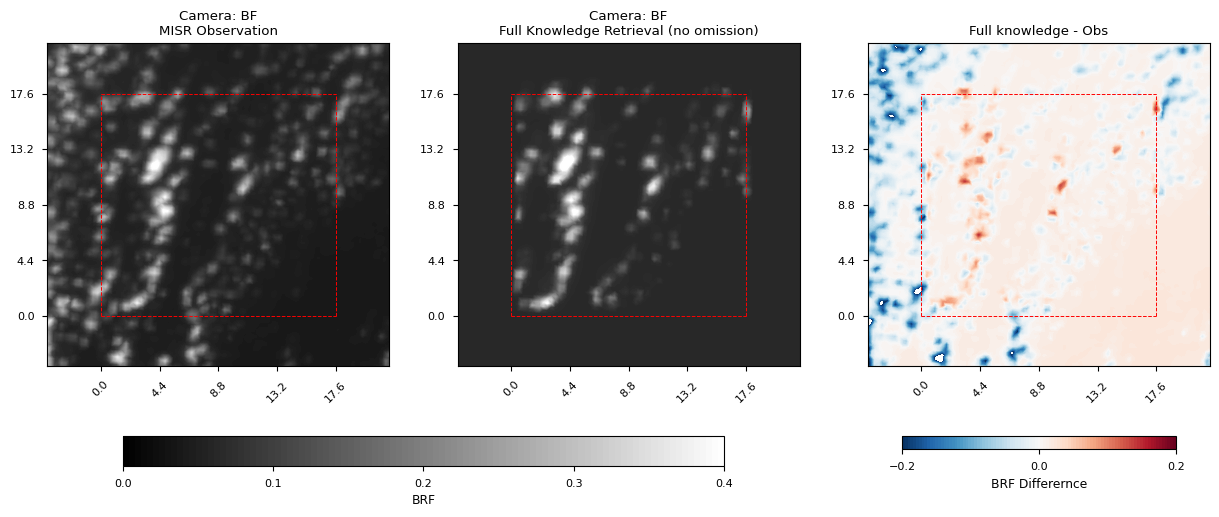

In [34]:
brf_kwargs = {
    'cmap': 'gray',
    'vmin': 0.0,
    'vmax': 0.4,
    'levels': np.linspace(0, 0.4, 100)
}
diff_kwargs = {
    'cmap': 'RdBu_r',
    'vmin': -0.2,
    'vmax': 0.2,
    'levels': np.linspace(-0.2, 0.2, 100)
}
f, ax = plt.subplots(1, 3, figsize=(15, 6))
bf_obs = rdef.obs['MISR']['sensor_list'][2].copy(deep=True)
bf_def = rdef.sensors_retrieval['MISR']['sensor_list'][2].copy(deep=True)
bf_loo = loo_sensor_dict['MISR']['sensor_list'][2].copy(deep=True)
bf_loo['brf'] = (bf_loo.I * np.pi) / bf_loo.mu0.data
p0 = ax[0].tricontourf(
    bf_obs.ray_x.data,
    bf_obs.ray_y.data,
    bf_obs.brf.data,
    **brf_kwargs
)
p1 = ax[1].tricontourf(
    bf_def.ray_x.data,
    bf_def.ray_y.data,
    bf_def.brf.data,
    **brf_kwargs
)
p2 = ax[2].tricontourf(
    bf_def.ray_x.data,
    bf_def.ray_y.data,
    bf_def.brf.data - bf_obs.brf.data,
    **diff_kwargs
)
plt.colorbar(p1, ax=ax[0:2], label='BRF', shrink=0.8, ticks=[0.0, 0.1, 0.2, 0.3, 0.4], location='bottom')
plt.colorbar(p2, ax=ax[2], label='BRF Differernce', shrink=0.8, ticks=[diff_kwargs['vmin'], 0, diff_kwargs['vmax']], location='bottom')
ax[0].set_title('Camera: BF\nMISR Observation')
ax[1].set_title('Camera: BF\nFull Knowledge Retrieval (no omission)')
ax[2].set_title('Full knowledge - Obs')

box_kwargs = {'ls':'--', 'lw':0.7, 'c':'r'}
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
for a in ax.flat:
    a.plot([0, 0], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [0, 0], **box_kwargs)
    a.plot([17.6, 17.6], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [17.6, 17.6], **box_kwargs)
    a.set_xticks(ticks)
    a.set_xticklabels(ticks, rotation=45)
    a.set_yticks(ticks)
    a.set_xlim([-4,17.6+4])
    a.set_ylim([-4,17.6+4])

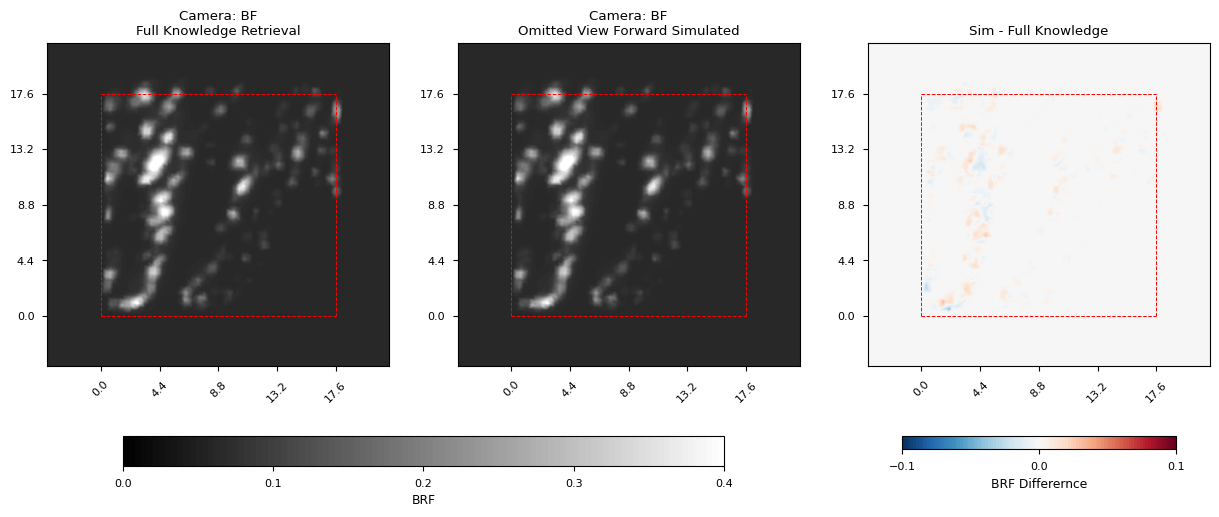

In [35]:
brf_kwargs = {
    'cmap': 'gray',
    'vmin': 0.0,
    'vmax': 0.4,
    'levels': np.linspace(0, 0.4, 100)
}
diff_kwargs = {
    'cmap': 'RdBu_r',
    'vmin': -0.1,
    'vmax': 0.1,
    'levels': np.linspace(-0.1, 0.1, 100)
}
f, ax = plt.subplots(1, 3, figsize=(15, 6))
bf_obs = rdef.obs['MISR']['sensor_list'][2].copy(deep=True)
bf_def = rdef.sensors_retrieval['MISR']['sensor_list'][2].copy(deep=True)
bf_loo = loo_sensor_dict['MISR']['sensor_list'][2].copy(deep=True)
bf_loo['brf'] = (bf_loo.I * np.pi) / bf_loo.mu0.data
p0 = ax[0].tricontourf(
    bf_def.ray_x.data,
    bf_def.ray_y.data,
    bf_def.brf.data,
    **brf_kwargs
)
p1 = ax[1].tricontourf(
    bf_loo.ray_x.data,
    bf_loo.ray_y.data,
    bf_loo.brf.data,
    **brf_kwargs
)
p2 = ax[2].tricontourf(
    bf_loo.ray_x.data,
    bf_loo.ray_y.data,
    bf_loo.brf.data - bf_def.brf.data,
    **diff_kwargs
)
plt.colorbar(p1, ax=ax[0:2], label='BRF', shrink=0.8, ticks=[0.0, 0.1, 0.2, 0.3, 0.4], location='bottom')
plt.colorbar(p2, ax=ax[2], label='BRF Differernce', shrink=0.8, ticks=[diff_kwargs['vmin'], 0, diff_kwargs['vmax']], location='bottom')
ax[0].set_title('Camera: BF\nFull Knowledge Retrieval')
ax[1].set_title('Camera: BF\nOmitted View Forward Simulated')
ax[2].set_title('Sim - Full Knowledge')

box_kwargs = {'ls':'--', 'lw':0.7, 'c':'r'}
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
for a in ax.flat:
    a.plot([0, 0], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [0, 0], **box_kwargs)
    a.plot([17.6, 17.6], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [17.6, 17.6], **box_kwargs)
    a.set_xticks(ticks)
    a.set_xticklabels(ticks, rotation=45)
    a.set_yticks(ticks)
    a.set_xlim([-4,17.6+4])
    a.set_ylim([-4,17.6+4])